In [3]:
import pandas as pd
import requests
import matplotlib.pyplot as plt

In [4]:


url = "https://data.sec.gov/api/xbrl/companyfacts/CIK0001048286.json"

headers = {
    "User-Agent": "Hotel Audit Project miguel.martinez11@gmail.com"
}

response = requests.get(url, headers=headers)

response.status_code

200

In [5]:
data=response.json()
type(data)

dict

In [6]:
print(data.keys())
print(data['cik'])
print(data['entityName'])
print(data['facts'].keys())

dict_keys(['cik', 'entityName', 'facts'])
1048286
MARRIOTT INTERNATIONAL INC /MD/
dict_keys(['dei', 'us-gaap', 'ffd'])


In [7]:
us_gaap=data['facts']['us-gaap']
print(len(us_gaap))

545


In [8]:
list(us_gaap.keys())[:20]

['AccountsAndFinancingReceivableAllowanceForCreditLoss',
 'AccountsNotesAndLoansReceivableNetCurrent',
 'AccountsPayable',
 'AccountsPayableCurrent',
 'AccountsPayableTradeCurrent',
 'AccumulatedDepreciationDepletionAndAmortizationPropertyPlantAndEquipment',
 'AccumulatedOtherComprehensiveIncomeLossAvailableForSaleSecuritiesAdjustmentNetOfTax',
 'AccumulatedOtherComprehensiveIncomeLossCumulativeChangesInNetGainLossFromCashFlowHedgesEffectNetOfTax',
 'AccumulatedOtherComprehensiveIncomeLossForeignCurrencyTranslationAdjustmentNetOfTax',
 'AccumulatedOtherComprehensiveIncomeLossNetOfTax',
 'AdditionalPaidInCapital',
 'AdditionalPaidInCapitalCommonStock',
 'AdjustmentsToAdditionalPaidInCapitalOther',
 'AdjustmentsToAdditionalPaidInCapitalTaxEffectFromShareBasedCompensation',
 'AdvertisingExpense',
 'AllocatedShareBasedCompensationExpense',
 'AllowanceForDoubtfulAccountsReceivableCurrent',
 'AllowanceForLoanAndLeaseLossesProvisionForLossNet',
 'AllowanceForNotesReceivable',
 'AmortizationOf

In [9]:
concept = us_gaap["AccountsPayableCurrent"]
print(type(concept))


<class 'dict'>


In [10]:
print(concept.keys())
print(concept['label'])
print(concept['description'])
print(concept['units'].keys())
def show_facts(facts, n=3):
    for item in facts[:n]:
        print(f"end:   {item['end']}")
        print(f"value: {item['val']:,}")
        print(f"accn:  {item['accn']}")
        print(f"fy:    {item.get('fy')}")
        print(f"fp:    {item.get('fp')}")
        print(f"form:  {item['form']}")
        print(f"filed: {item['filed']}")
        print("-" * 40)
show_facts(concept["units"]["USD"])


dict_keys(['label', 'description', 'units'])
Accounts Payable, Current
Carrying value as of the balance sheet date of liabilities incurred (and for which invoices have typically been received) and payable to vendors for goods and services received that are used in an entity's business. Used to reflect the current portion of the liabilities (due within one year or within the normal operating cycle if longer).
dict_keys(['USD'])
end:   2009-01-02
value: 704,000,000
accn:  0001193125-10-030603
fy:    2009
fp:    FY
form:  10-K
filed: 2010-02-12
----------------------------------------
end:   2009-01-02
value: 704,000,000
accn:  0001193125-09-206036
fy:    2009
fp:    Q3
form:  10-Q
filed: 2009-10-09
----------------------------------------
end:   2009-09-11
value: 559,000,000
accn:  0001193125-09-206036
fy:    2009
fp:    Q3
form:  10-Q
filed: 2009-10-09
----------------------------------------


In [11]:
print([name for name in us_gaap if "Revenue" in name][:30])
print([name for name in us_gaap if "Receivable" in name][:30])

['ContractWithCustomerLiabilityCumulativeCatchUpAdjustmentToRevenueChangeInEstimateOfTransactionPrice', 'ContractWithCustomerLiabilityRevenueRecognized', 'DeferredRevenue', 'DisposalGroupIncludingDiscontinuedOperationRevenue', 'EquityMethodInvestmentSummarizedFinancialInformationNetSalesOrGrossRevenue', 'EquityMethodInvestmentSummarizedFinancialInformationRevenue', 'FranchiseRevenue', 'InterestRevenueExpenseNet', 'LicensesRevenue', 'ManagementFeesBaseRevenue', 'ManagementFeesIncentiveRevenue', 'ReimbursementRevenue', 'RevenueFromLeasedAndOwnedHotels', 'Revenues', 'TimeShareRevenue']
['AccountsAndFinancingReceivableAllowanceForCreditLoss', 'AccountsNotesAndLoansReceivableNetCurrent', 'AllowanceForDoubtfulAccountsReceivableCurrent', 'AllowanceForNotesReceivable', 'FinancingReceivableAllowanceForCreditLosses', 'FinancingReceivableAllowanceForCreditLossesPeriodIncreaseDecrease', 'FinancingReceivableAllowanceForCreditLossesProvisions', 'FinancingReceivableAllowanceForCreditLossesWriteOffs',

In [12]:
revenue = us_gaap["Revenues"]

print("Label:", revenue["label"])
print("Description:", revenue["description"])
print("Units:", revenue["units"].keys())

print([name for name in us_gaap if "AccountsReceivable" in name])

print([name for name in us_gaap if "Receivable" in name and "Current" in name])

Label: Revenues
Description: Amount of revenue recognized from goods sold, services rendered, insurance premiums, or other activities that constitute an earning process. Includes, but is not limited to, investment and interest income before deduction of interest expense when recognized as a component of revenue, and sales and trading gain (loss).
Units: dict_keys(['USD'])
['AllowanceForDoubtfulAccountsReceivableCurrent', 'AllowanceForDoubtfulAccountsReceivable']
['AccountsNotesAndLoansReceivableNetCurrent', 'AllowanceForDoubtfulAccountsReceivableCurrent', 'NotesAndLoansReceivableNetCurrent']


In [13]:
revenue = us_gaap["Revenues"]
show_facts(revenue["units"]["USD"], n=10)

end:   2007-12-28
value: 12,990,000,000
accn:  0001193125-10-030603
fy:    2009
fp:    FY
form:  10-K
filed: 2010-02-12
----------------------------------------
end:   2008-06-13
value: 6,132,000,000
accn:  0001193125-09-150935
fy:    2009
fp:    Q2
form:  10-Q
filed: 2009-07-17
----------------------------------------
end:   2008-06-13
value: 3,185,000,000
accn:  0001193125-09-150935
fy:    2009
fp:    Q2
form:  10-Q
filed: 2009-07-17
----------------------------------------
end:   2008-09-05
value: 9,095,000,000
accn:  0001193125-09-206036
fy:    2009
fp:    Q3
form:  10-Q
filed: 2009-10-09
----------------------------------------
end:   2008-09-05
value: 2,963,000,000
accn:  0001193125-09-206036
fy:    2009
fp:    Q3
form:  10-Q
filed: 2009-10-09
----------------------------------------
end:   2009-01-02
value: 12,879,000,000
accn:  0001193125-10-030603
fy:    2009
fp:    FY
form:  10-K
filed: 2010-02-12
----------------------------------------
end:   2009-01-02
value: 12,879,000,00

In [14]:
receivable = us_gaap["AccountsNotesAndLoansReceivableNetCurrent"]

print("Label:", receivable["label"])
print("Description:", receivable["description"])
print("Units:", receivable["units"].keys())

print(show_facts(receivable["units"]["USD"], n=10))

Label: Accounts and Financing Receivable, after Allowance for Credit Loss, Current
Description: Amount, after allowance for credit loss, of accounts and financing receivables, classified as current. Includes, but is not limited to, notes and loan receivable.
Units: dict_keys(['USD'])
end:   2009-01-02
value: 898,000,000
accn:  0001193125-09-150935
fy:    2009
fp:    Q2
form:  10-Q
filed: 2009-07-17
----------------------------------------
end:   2009-01-02
value: 898,000,000
accn:  0001193125-09-206036
fy:    2009
fp:    Q3
form:  10-Q
filed: 2009-10-09
----------------------------------------
end:   2009-01-02
value: 898,000,000
accn:  0001193125-10-030603
fy:    2009
fp:    FY
form:  10-K
filed: 2010-02-12
----------------------------------------
end:   2009-06-19
value: 863,000,000
accn:  0001193125-09-150935
fy:    2009
fp:    Q2
form:  10-Q
filed: 2009-07-17
----------------------------------------
end:   2009-09-11
value: 908,000,000
accn:  0001193125-09-206036
fy:    2009
fp:   

In [15]:
print(us_gaap["AccountsNotesAndLoansReceivableNetCurrent"]["label"])
print(us_gaap["AccountsNotesAndLoansReceivableNetCurrent"]["description"])

Accounts and Financing Receivable, after Allowance for Credit Loss, Current
Amount, after allowance for credit loss, of accounts and financing receivables, classified as current. Includes, but is not limited to, notes and loan receivable.


In [16]:
accounts = us_gaap["AccountsNotesAndLoansReceivableNetCurrent"]

print("Label:", accounts["label"])
print("Description:", accounts["description"])
print("Units:", accounts["units"].keys())
print(show_facts(accounts["units"]["USD"], n=10))

Label: Accounts and Financing Receivable, after Allowance for Credit Loss, Current
Description: Amount, after allowance for credit loss, of accounts and financing receivables, classified as current. Includes, but is not limited to, notes and loan receivable.
Units: dict_keys(['USD'])
end:   2009-01-02
value: 898,000,000
accn:  0001193125-09-150935
fy:    2009
fp:    Q2
form:  10-Q
filed: 2009-07-17
----------------------------------------
end:   2009-01-02
value: 898,000,000
accn:  0001193125-09-206036
fy:    2009
fp:    Q3
form:  10-Q
filed: 2009-10-09
----------------------------------------
end:   2009-01-02
value: 898,000,000
accn:  0001193125-10-030603
fy:    2009
fp:    FY
form:  10-K
filed: 2010-02-12
----------------------------------------
end:   2009-06-19
value: 863,000,000
accn:  0001193125-09-150935
fy:    2009
fp:    Q2
form:  10-Q
filed: 2009-07-17
----------------------------------------
end:   2009-09-11
value: 908,000,000
accn:  0001193125-09-206036
fy:    2009
fp:   

In [17]:
[name for name in us_gaap if "Receivable" in name]

['AccountsAndFinancingReceivableAllowanceForCreditLoss',
 'AccountsNotesAndLoansReceivableNetCurrent',
 'AllowanceForDoubtfulAccountsReceivableCurrent',
 'AllowanceForNotesReceivable',
 'FinancingReceivableAllowanceForCreditLosses',
 'FinancingReceivableAllowanceForCreditLossesPeriodIncreaseDecrease',
 'FinancingReceivableAllowanceForCreditLossesProvisions',
 'FinancingReceivableAllowanceForCreditLossesWriteOffs',
 'FinancingReceivableRecordedInvestmentPastDue',
 'ImpairedFinancingReceivableAverageRecordedInvestment',
 'ImpairedFinancingReceivableRecordedInvestment',
 'ImpairedFinancingReceivableWithNoRelatedAllowanceRecordedInvestment',
 'NotesAndLoansReceivableNetCurrent',
 'NotesAndLoansReceivableNetNoncurrent',
 'NotesReceivableNet',
 'OtherReceivables',
 'ProceedsFromSaleAndCollectionOfLoansReceivable',
 'ProceedsFromSaleAndCollectionOfNotesReceivable',
 'ReceivableWithImputedInterestDiscount',
 'AllowanceForDoubtfulAccountsReceivable']

In [18]:
for concept_name in [
    "AccountsNotesAndLoansReceivableNetCurrent",
    "NotesAndLoansReceivableNetCurrent",
    "OtherReceivables"
]:
    concept = us_gaap[concept_name]

    print("=" * 70)
    print("CONCEPT:", concept_name)
    print("LABEL:", concept["label"])
    print("DESCRIPTION:", concept["description"])
    print("UNITS:", concept["units"].keys())

CONCEPT: AccountsNotesAndLoansReceivableNetCurrent
LABEL: Accounts and Financing Receivable, after Allowance for Credit Loss, Current
DESCRIPTION: Amount, after allowance for credit loss, of accounts and financing receivables, classified as current. Includes, but is not limited to, notes and loan receivable.
UNITS: dict_keys(['USD'])
CONCEPT: NotesAndLoansReceivableNetCurrent
LABEL: Financing Receivable, after Allowance for Credit Loss, Current
DESCRIPTION: Amount, after allowance for credit loss, of financing receivable, classified as current. Includes, but is not limited to, notes and loan receivable.
UNITS: dict_keys(['USD'])
CONCEPT: OtherReceivables
LABEL: Other Receivables
DESCRIPTION: Amount due from parties in nontrade transactions, classified as other.
UNITS: dict_keys(['USD'])


In [19]:
facts = us_gaap["AccountsNotesAndLoansReceivableNetCurrent"]["units"]["USD"]
print(len(facts))
print(show_facts(facts, n=20))

144
end:   2009-01-02
value: 898,000,000
accn:  0001193125-09-150935
fy:    2009
fp:    Q2
form:  10-Q
filed: 2009-07-17
----------------------------------------
end:   2009-01-02
value: 898,000,000
accn:  0001193125-09-206036
fy:    2009
fp:    Q3
form:  10-Q
filed: 2009-10-09
----------------------------------------
end:   2009-01-02
value: 898,000,000
accn:  0001193125-10-030603
fy:    2009
fp:    FY
form:  10-K
filed: 2010-02-12
----------------------------------------
end:   2009-06-19
value: 863,000,000
accn:  0001193125-09-150935
fy:    2009
fp:    Q2
form:  10-Q
filed: 2009-07-17
----------------------------------------
end:   2009-09-11
value: 908,000,000
accn:  0001193125-09-206036
fy:    2009
fp:    Q3
form:  10-Q
filed: 2009-10-09
----------------------------------------
end:   2010-01-01
value: 838,000,000
accn:  0001193125-10-030603
fy:    2009
fp:    FY
form:  10-K
filed: 2010-02-12
----------------------------------------
end:   2010-01-01
value: 838,000,000
accn:  0001

In [20]:
for item in facts:
    if item.get("fy") in range(2015, 2026) and item.get("form") == "10-K":
        print(
            item["end"],
            item["val"],
            item.get("fy"),
            item.get("fp"),
            item["form"],
            item["filed"]
        )

2014-12-31 1100000000 2015 FY 10-K 2016-02-18
2015-12-31 1103000000 2015 FY 10-K 2016-02-18
2015-12-31 1103000000 2016 FY 10-K 2017-02-21
2016-12-31 1695000000 2016 FY 10-K 2017-02-21
2016-12-31 1695000000 2017 FY 10-K 2018-02-15
2017-12-31 1991000000 2017 FY 10-K 2018-02-15
2017-12-31 1973000000 2018 FY 10-K 2019-03-01
2018-12-31 2133000000 2018 FY 10-K 2019-03-01
2018-12-31 2133000000 2019 FY 10-K 2020-02-27
2019-12-31 2395000000 2019 FY 10-K 2020-02-27
2019-12-31 2395000000 2020 FY 10-K 2021-02-18
2020-12-31 1768000000 2020 FY 10-K 2021-02-18
2020-12-31 1768000000 2021 FY 10-K 2022-02-15
2021-12-31 1982000000 2021 FY 10-K 2022-02-15
2021-12-31 1982000000 2022 FY 10-K 2023-02-14
2022-12-31 2571000000 2022 FY 10-K 2023-02-14
2022-12-31 2571000000 2023 FY 10-K 2024-02-13
2023-12-31 2712000000 2023 FY 10-K 2024-02-13
2023-12-31 2712000000 2024 FY 10-K 2025-02-11
2024-12-31 2795000000 2024 FY 10-K 2025-02-11
2024-12-31 2795000000 2025 FY 10-K 2026-02-10
2025-12-31 2909000000 2025 FY 10-K

In [21]:
annual_facts = [
    item
    for item in facts
    if item.get("fy") in range(2015, 2026)
    and item.get("fp") == "FY"
    and item.get("form") == "10-K"
]

print(len(annual_facts))
for item in annual_facts:
    print(
        "FY:", item["fy"],
        "| end:", item["end"],
        "| value:", item["val"],
        "| filed:", item["filed"]
    )

22
FY: 2015 | end: 2014-12-31 | value: 1100000000 | filed: 2016-02-18
FY: 2015 | end: 2015-12-31 | value: 1103000000 | filed: 2016-02-18
FY: 2016 | end: 2015-12-31 | value: 1103000000 | filed: 2017-02-21
FY: 2016 | end: 2016-12-31 | value: 1695000000 | filed: 2017-02-21
FY: 2017 | end: 2016-12-31 | value: 1695000000 | filed: 2018-02-15
FY: 2017 | end: 2017-12-31 | value: 1991000000 | filed: 2018-02-15
FY: 2018 | end: 2017-12-31 | value: 1973000000 | filed: 2019-03-01
FY: 2018 | end: 2018-12-31 | value: 2133000000 | filed: 2019-03-01
FY: 2019 | end: 2018-12-31 | value: 2133000000 | filed: 2020-02-27
FY: 2019 | end: 2019-12-31 | value: 2395000000 | filed: 2020-02-27
FY: 2020 | end: 2019-12-31 | value: 2395000000 | filed: 2021-02-18
FY: 2020 | end: 2020-12-31 | value: 1768000000 | filed: 2021-02-18
FY: 2021 | end: 2020-12-31 | value: 1768000000 | filed: 2022-02-15
FY: 2021 | end: 2021-12-31 | value: 1982000000 | filed: 2022-02-15
FY: 2022 | end: 2021-12-31 | value: 1982000000 | filed: 202

In [22]:
annual_current = [
    item
    for item in annual_facts
    if item["fy"] == int(item["end"][:4])
]
print(len(annual_current))
for item in annual_current:
    print(
        "FY:", item["fy"],
        "| end:", item["end"],
        "| value:", item["val"],
        "| filed:", item["filed"]
    )

11
FY: 2015 | end: 2015-12-31 | value: 1103000000 | filed: 2016-02-18
FY: 2016 | end: 2016-12-31 | value: 1695000000 | filed: 2017-02-21
FY: 2017 | end: 2017-12-31 | value: 1991000000 | filed: 2018-02-15
FY: 2018 | end: 2018-12-31 | value: 2133000000 | filed: 2019-03-01
FY: 2019 | end: 2019-12-31 | value: 2395000000 | filed: 2020-02-27
FY: 2020 | end: 2020-12-31 | value: 1768000000 | filed: 2021-02-18
FY: 2021 | end: 2021-12-31 | value: 1982000000 | filed: 2022-02-15
FY: 2022 | end: 2022-12-31 | value: 2571000000 | filed: 2023-02-14
FY: 2023 | end: 2023-12-31 | value: 2712000000 | filed: 2024-02-13
FY: 2024 | end: 2024-12-31 | value: 2795000000 | filed: 2025-02-11
FY: 2025 | end: 2025-12-31 | value: 2909000000 | filed: 2026-02-10


In [23]:
from datetime import date


def get_annual_facts(us_gaap, concept_name, start_year, end_year):
    """
    Extract one annual observation per fiscal year from SEC Company Facts.

    Handles:
    - instant facts: balance-sheet items
    - duration facts: income-statement items
    """

    facts = us_gaap[concept_name]["units"]["USD"]

    candidates = [
        item
        for item in facts
        if (
            item.get("fy") is not None
            and start_year <= item["fy"] <= end_year
            and item.get("form") == "10-K"
        )
    ]

    annual_facts = []

    for fy in range(start_year, end_year + 1):

        year_facts = [
            item
            for item in candidates
            if item["fy"] == fy
        ]

        if not year_facts:
            continue

        # --------------------------------------------------
        # Duration facts: Revenue, Net Income, etc.
        # --------------------------------------------------

        duration_facts = [
            item
            for item in year_facts
            if "start" in item
        ]

        if duration_facts:

            annual_candidates = []

            for item in duration_facts:
                start = date.fromisoformat(item["start"])
                end = date.fromisoformat(item["end"])

                duration_days = (end - start).days

                # Approximately one fiscal year.
                # Allows 52/53-week fiscal years.
                if 300 <= duration_days <= 400:
                    annual_candidates.append(item)

            if not annual_candidates:
                continue

            # If there are comparative annual facts,
            # choose the one with the latest end date.
            annual = max(
                annual_candidates,
                key=lambda item: item["end"]
            )

        # --------------------------------------------------
        # Instant facts: Receivables, Assets, etc.
        # --------------------------------------------------

        else:

            instant_candidates = [
                item
                for item in year_facts
                if "start" not in item
            ]

            if not instant_candidates:
                continue

            # Choose the latest balance-sheet date.
            annual = max(
                instant_candidates,
                key=lambda item: item["end"]
            )

        annual_facts.append(annual)

    return annual_facts

In [24]:
receivables = get_annual_facts(
    us_gaap,
    "AccountsNotesAndLoansReceivableNetCurrent",
    2015,
    2025
)
print(len(receivables))
for item in receivables:
    print(
        "FY:", item["fy"],
        "| end:", item["end"],
        "| value:", item["val"],
        "| filed:", item["filed"]
    )

11
FY: 2015 | end: 2015-12-31 | value: 1103000000 | filed: 2016-02-18
FY: 2016 | end: 2016-12-31 | value: 1695000000 | filed: 2017-02-21
FY: 2017 | end: 2017-12-31 | value: 1991000000 | filed: 2018-02-15
FY: 2018 | end: 2018-12-31 | value: 2133000000 | filed: 2019-03-01
FY: 2019 | end: 2019-12-31 | value: 2395000000 | filed: 2020-02-27
FY: 2020 | end: 2020-12-31 | value: 1768000000 | filed: 2021-02-18
FY: 2021 | end: 2021-12-31 | value: 1982000000 | filed: 2022-02-15
FY: 2022 | end: 2022-12-31 | value: 2571000000 | filed: 2023-02-14
FY: 2023 | end: 2023-12-31 | value: 2712000000 | filed: 2024-02-13
FY: 2024 | end: 2024-12-31 | value: 2795000000 | filed: 2025-02-11
FY: 2025 | end: 2025-12-31 | value: 2909000000 | filed: 2026-02-10


In [25]:
revenue = get_annual_facts(
    us_gaap,
    "Revenues",
    2015,
    2025
)

print(len(revenue))
for item in revenue:
    print(
        "FY:", item["fy"],
        "| start:", item["start"],
        "| end:", item["end"],
        "| value:", item["val"]
    )

11
FY: 2015 | start: 2015-01-01 | end: 2015-12-31 | value: 14486000000
FY: 2016 | start: 2016-01-01 | end: 2016-12-31 | value: 17072000000
FY: 2017 | start: 2017-01-01 | end: 2017-12-31 | value: 22894000000
FY: 2018 | start: 2018-01-01 | end: 2018-12-31 | value: 20758000000
FY: 2019 | start: 2019-01-01 | end: 2019-12-31 | value: 20972000000
FY: 2020 | start: 2020-01-01 | end: 2020-12-31 | value: 10571000000
FY: 2021 | start: 2021-01-01 | end: 2021-12-31 | value: 13857000000
FY: 2022 | start: 2022-01-01 | end: 2022-12-31 | value: 20773000000
FY: 2023 | start: 2023-01-01 | end: 2023-12-31 | value: 23713000000
FY: 2024 | start: 2024-01-01 | end: 2024-12-31 | value: 25100000000
FY: 2025 | start: 2025-01-01 | end: 2025-12-31 | value: 26186000000


In [26]:
print(f"{'FY':<6} {'Revenue':>15} {'Receivable':>15}")
print("-" * 38)

for rev, ar in zip(revenue, receivables):
    print(
        f"{rev['fy']:<6} "
        f"{rev['val']:>15,} "
        f"{ar['val']:>15,}"
    )

FY             Revenue      Receivable
--------------------------------------
2015    14,486,000,000   1,103,000,000
2016    17,072,000,000   1,695,000,000
2017    22,894,000,000   1,991,000,000
2018    20,758,000,000   2,133,000,000
2019    20,972,000,000   2,395,000,000
2020    10,571,000,000   1,768,000,000
2021    13,857,000,000   1,982,000,000
2022    20,773,000,000   2,571,000,000
2023    23,713,000,000   2,712,000,000
2024    25,100,000,000   2,795,000,000
2025    26,186,000,000   2,909,000,000


In [27]:
import pandas as pd

df = pd.DataFrame({
    "year": [item["fy"] for item in revenue],
    "revenue": [item["val"] for item in revenue],
    "receivables": [item["val"] for item in receivables],
})

print(df.info())
print(df.head())


<class 'pandas.DataFrame'>
RangeIndex: 11 entries, 0 to 10
Data columns (total 3 columns):
 #   Column       Non-Null Count  Dtype
---  ------       --------------  -----
 0   year         11 non-null     int64
 1   revenue      11 non-null     int64
 2   receivables  11 non-null     int64
dtypes: int64(3)
memory usage: 396.0 bytes
None
   year      revenue  receivables
0  2015  14486000000   1103000000
1  2016  17072000000   1695000000
2  2017  22894000000   1991000000
3  2018  20758000000   2133000000
4  2019  20972000000   2395000000


In [28]:
print(df["year"].is_unique)
print(df["year"].min(), df["year"].max())

True
2015 2025


In [29]:
df["revenue_growth"] = df["revenue"].pct_change()
df

,year,revenue,receivables,revenue_growth
0,2015,14486000000,1103000000,NaN
1,2016,17072000000,1695000000,0.178517
2,2017,22894000000,1991000000,0.341026
3,2018,20758000000,2133000000,-0.093300
4,2019,20972000000,2395000000,0.010309
5,2020,10571000000,1768000000,-0.495947
6,2021,13857000000,1982000000,0.310850
7,2022,20773000000,2571000000,0.499098
8,2023,23713000000,2712000000,0.141530
9,2024,25100000000,2795000000,0.058491


In [30]:
df[["year", "revenue", "revenue_growth"]]

,year,revenue,revenue_growth
0,2015,14486000000,NaN
1,2016,17072000000,0.178517
2,2017,22894000000,0.341026
3,2018,20758000000,-0.093300
4,2019,20972000000,0.010309
5,2020,10571000000,-0.495947
6,2021,13857000000,0.310850
7,2022,20773000000,0.499098
8,2023,23713000000,0.141530
9,2024,25100000000,0.058491


In [31]:
df["revenue_growth"].round(4)
pd.set_option("display.precision", 4)
df

,year,revenue,receivables,revenue_growth
0,2015,14486000000,1103000000,NaN
1,2016,17072000000,1695000000,0.1785
2,2017,22894000000,1991000000,0.3410
3,2018,20758000000,2133000000,-0.0933
4,2019,20972000000,2395000000,0.0103
5,2020,10571000000,1768000000,-0.4959
6,2021,13857000000,1982000000,0.3109
7,2022,20773000000,2571000000,0.4991
8,2023,23713000000,2712000000,0.1415
9,2024,25100000000,2795000000,0.0585


In [32]:
df["receivables_growth"] = df["receivables"].pct_change()
df[["year", "receivables", "receivables_growth"]]

,year,receivables,receivables_growth
0,2015,1103000000,NaN
1,2016,1695000000,0.5367
2,2017,1991000000,0.1746
3,2018,2133000000,0.0713
4,2019,2395000000,0.1228
5,2020,1768000000,-0.2618
6,2021,1982000000,0.1210
7,2022,2571000000,0.2972
8,2023,2712000000,0.0548
9,2024,2795000000,0.0306


In [33]:
df['divergence'] = df['revenue_growth'] - df['receivables_growth']


In [34]:
df[["year", "revenue_growth", "receivables_growth", "divergence"]]

,year,revenue_growth,receivables_growth,divergence
0,2015,NaN,NaN,NaN
1,2016,0.1785,0.5367,-0.3582
2,2017,0.3410,0.1746,0.1664
3,2018,-0.0933,0.0713,-0.1646
4,2019,0.0103,0.1228,-0.1125
5,2020,-0.4959,-0.2618,-0.2342
6,2021,0.3109,0.1210,0.1898
7,2022,0.4991,0.2972,0.2019
8,2023,0.1415,0.0548,0.0867
9,2024,0.0585,0.0306,0.0279


In [35]:
df["divergence"].describe()

count    10.0000
mean     -0.0194
std       0.1920
min      -0.3582
25%      -0.1516
50%       0.0152
75%       0.1465
max       0.2019
Name: divergence, dtype: float64

In [36]:
df.loc[
    df["divergence"].idxmin(),
    ["year", "revenue_growth", "receivables_growth", "divergence"]
]

year                  2016.0000
revenue_growth           0.1785
receivables_growth       0.5367
divergence              -0.3582
Name: 1, dtype: float64

In [37]:
df.loc[
    df["divergence"].idxmax(),
    ["year", "revenue_growth", "receivables_growth", "divergence"]
]

year                  2022.0000
revenue_growth           0.4991
receivables_growth       0.2972
divergence               0.2019
Name: 7, dtype: float64

In [38]:
df.sort_values("divergence")[
    ["year", "revenue_growth", "receivables_growth", "divergence"]
]

,year,revenue_growth,receivables_growth,divergence
1,2016,0.1785,0.5367,-0.3582
5,2020,-0.4959,-0.2618,-0.2342
3,2018,-0.0933,0.0713,-0.1646
4,2019,0.0103,0.1228,-0.1125
10,2025,0.0433,0.0408,0.0025
9,2024,0.0585,0.0306,0.0279
8,2023,0.1415,0.0548,0.0867
2,2017,0.3410,0.1746,0.1664
6,2021,0.3109,0.1210,0.1898
7,2022,0.4991,0.2972,0.2019


In [39]:
display_df = df[
    ["year", "revenue_growth", "receivables_growth", "divergence"]
].copy()

display_df[
    ["revenue_growth", "receivables_growth", "divergence"]
] *= 100

display_df.sort_values("divergence").round(2)

,year,revenue_growth,receivables_growth,divergence
1,2016,17.85,53.67,-35.82
5,2020,-49.59,-26.18,-23.42
3,2018,-9.33,7.13,-16.46
4,2019,1.03,12.28,-11.25
10,2025,4.33,4.08,0.25
9,2024,5.85,3.06,2.79
8,2023,14.15,5.48,8.67
2,2017,34.10,17.46,16.64
6,2021,31.09,12.10,18.98
7,2022,49.91,29.72,20.19


In [40]:
q1 = df["divergence"].quantile(0.25)
q3 = df["divergence"].quantile(0.75)

iqr = q3 - q1

q1, q3, iqr

(np.float64(-0.151595977563513),
 np.float64(0.14646807921198401),
 np.float64(0.298064056775497))

In [41]:
lower_bound = q1 - 1.5 * iqr
upper_bound = q3 + 1.5 * iqr

lower_bound, upper_bound

(np.float64(-0.5986920627267585), np.float64(0.5935641643752295))

BoxPlot on the divergence.

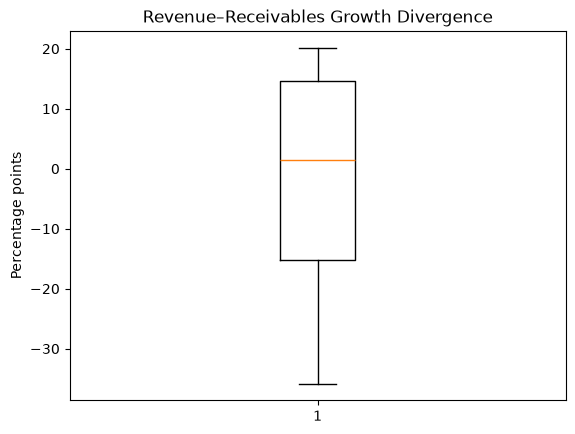

In [42]:
plt.boxplot(df["divergence"].dropna() * 100)

plt.title("Revenue–Receivables Growth Divergence")
plt.ylabel("Percentage points")

plt.show()

Plot Divergence by Year

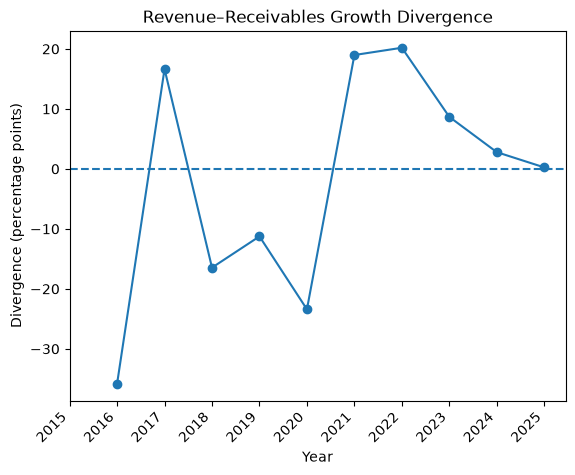

In [43]:
plt.plot(
    df["year"],
    df["divergence"] * 100,
    marker="o"
)

plt.axhline(0, linestyle="--")

plt.title("Revenue–Receivables Growth Divergence")
plt.xlabel("Year")
plt.ylabel("Divergence (percentage points)")

plt.xticks(df["year"])
plt.xticks(df["year"], rotation=45, ha="right")

plt.show()

In [44]:
df["period"] = pd.cut(
    df["year"],
    bins=[2015, 2019, 2020, 2025],
    labels=["Pre-2020", "2020", "Post-2020"]
)
df[["year", "divergence", "period"]]

,year,divergence,period
0,2015,NaN,NaN
1,2016,-0.3582,Pre-2020
2,2017,0.1664,Pre-2020
3,2018,-0.1646,Pre-2020
4,2019,-0.1125,Pre-2020
5,2020,-0.2342,2020
6,2021,0.1898,Post-2020
7,2022,0.2019,Post-2020
8,2023,0.0867,Post-2020
9,2024,0.0279,Post-2020


In [45]:
df.groupby("period", observed=True)["divergence"].mean() * 100

period
Pre-2020    -11.7237
2020        -23.4152
Post-2020    10.1757
Name: divergence, dtype: float64

In [46]:
df["abs_divergence"] = df["divergence"].abs()
df.groupby("period", observed=True)["abs_divergence"].mean() * 100

period
Pre-2020     20.0435
2020         23.4152
Post-2020    10.1757
Name: abs_divergence, dtype: float64

In [47]:
df.groupby("period", observed=True)["divergence"].agg(
    ["mean", "std", "count"]
)

,mean,std,count
period,,,
Pre-2020,-0.1172,0.2166,4
2020,-0.2342,NaN,1
Post-2020,0.1018,0.0913,5


In [48]:
df.groupby("period", observed=True)["abs_divergence"].agg(
    ["mean", "std", "count"]
)

,mean,std,count
period,,,
Pre-2020,0.2004,0.1081,4
2020,0.2342,NaN,1
Post-2020,0.1018,0.0913,5


For Marriott, revenue and receivables growth rates were more closely aligned on average during 2021–2025 than during 2016–2019, as measured by absolute growth-rate divergence.